# Prediksi Next Click Wikipedia Menggunakan Hybrid Graph Routing, Semantic Pair Ranking, dan Discounted Reachability

## Tim RIZZZ

**Universitas Airlangga**

### Anggota Kelompok

- Timotius Christopher Patrick Sihombing
- Raphael Angelo Adikara Purnama
- Aqila Malfa Zahira

Notebook ini memprediksi artikel yang akan diklik berikutnya ketika navigator berada pada suatu artikel Wikipedia dan sedang menuju artikel target. Prediksi dibatasi pada link biru yang tersedia di halaman saat ini.

Pipeline final menggabungkan tiga sumber informasi:

1. **Graph routing:** reverse BFS mengukur jarak setiap kandidat menuju target dan shortest-path mass menilai banyaknya rute terpendek.
2. **Semantic pair ranking:** embedding judul dan kategori kandidat-target dipadukan dengan fitur tabular melalui LightGBM.
3. **Discounted reachability:** random walk terdiskonto mengukur kualitas seluruh rute pendek sambil memperhitungkan tingkat percabangan halaman.

Evaluasi menggunakan exact-match accuracy dan `GroupKFold(target_article_id)` agar artikel target pada validation tidak muncul dalam training fold. Notebook menghasilkan submission berformat `state_id,predicted_next_article_id`.

## 1. Konfigurasi dan Reproducibility

Bagian ini menetapkan seed, jumlah fold, lokasi dataset, mode lokal/Kaggle, dan direktori output. Local execution memakai environment proyek yang sudah tersedia, sedangkan Kaggle dapat membaca competition dataset serta cache preprocessing yang dilampirkan sebagai input.

Pipeline final berjalan di CPU. OCR dan encoding artikel tidak diulang karena hasil preprocessing telah disimpan sebagai artifact reusable.

In [1]:
from __future__ import annotations

import gc, json, math, os, shutil, time, warnings
from collections import Counter, defaultdict, deque
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Embed every EDA figure inside the executed notebook.
get_ipython().run_line_magic('matplotlib', 'inline')
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupKFold

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')

IS_KAGGLE = Path('/kaggle/working').exists()
LOCAL_SMOKE_MODE = (not IS_KAGGLE) and os.getenv('DATATON_LOCAL_SMOKE','0') == '1'
N_SPLITS = 3
MAX_CANDIDATES = 100
N_SOFT_SEARCH = 0
N_HARDMIN_SEARCH = 0
RUN_LAMBDARANK = False
LOCAL_SMOKE_TARGETS = 30
START_TIME = time.time()

KAGGLE_COMPETITION_PATH = Path('/kaggle/input/competitions/datathon-task-2/dataset-task2')
KAGGLE_REUSE_PATH = Path('/kaggle/input/datasets/timotiuspatrick/datatonday2output/datathon_task2_v1_reusable')
KAGGLE_REUSE_SHORT_PATH = Path('/kaggle/input/datatonday2output/datathon_task2_v1_reusable')
LOCAL_PATRICK_PATH = Path('/Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick')
LOCAL_DATA_PATH = LOCAL_PATRICK_PATH.parent/'dataset-task2'
LOCAL_REUSE_PATH = LOCAL_PATRICK_PATH/'output/v1/datathon_task2_v1_reusable'
LOCAL_OUTPUT_PATH = LOCAL_PATRICK_PATH/'output/v6'

DATA_PATH = KAGGLE_COMPETITION_PATH if KAGGLE_COMPETITION_PATH.exists() else LOCAL_DATA_PATH
OUTPUT_DIR = Path('/kaggle/working/datathon_task2_v6') if IS_KAGGLE else LOCAL_OUTPUT_PATH
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def valid_reuse(path):
    return (path/'manifest.json').exists() and (path/'task2_v1_link_candidates.csv').exists()

reuse_candidates = [KAGGLE_REUSE_PATH, KAGGLE_REUSE_SHORT_PATH, LOCAL_REUSE_PATH] if IS_KAGGLE else [LOCAL_REUSE_PATH, KAGGLE_REUSE_PATH, KAGGLE_REUSE_SHORT_PATH]
REUSE_PATH = next((p for p in reuse_candidates if valid_reuse(p)), None)
if REUSE_PATH is None and Path('/kaggle/input').exists():
    discovered = [p.parent for p in Path('/kaggle/input').rglob('manifest.json') if valid_reuse(p.parent)]
    REUSE_PATH = discovered[0] if discovered else None
if REUSE_PATH is None:
    raise FileNotFoundError('Reusable V1 folder tidak ditemukan. Attach Kaggle Dataset datatonday2output terlebih dahulu.')

print('Competition data :', DATA_PATH)
print('Reusable V1 data :', REUSE_PATH)
print('Output directory :', OUTPUT_DIR)
execution_label = 'LOCAL SMOKE/SUBSET' if LOCAL_SMOKE_MODE else ('KAGGLE FULL' if IS_KAGGLE else 'LOCAL FULL')
print('Execution mode   :', execution_label)
print('Search budgets   :', N_SOFT_SEARCH, '+', N_HARDMIN_SEARCH)
print('LightGBM enabled :', RUN_LAMBDARANK)

Competition data : /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/dataset-task2
Reusable V1 data : /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/output/v1/datathon_task2_v1_reusable
Output directory : /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/output/v6
Execution mode   : LOCAL FULL
Search budgets   : 0 + 0
LightGBM enabled : False


## 2. Pengenalan Dataset dan Pemeriksaan Input

Dataset terdiri dari metadata artikel, kategori, state train berlabel, state test, screenshot setiap artikel, dan contoh submission. Pemeriksaan awal memastikan ID artikel valid, urutan `state_id` konsisten, target train dan test terpisah, serta reusable OCR bundle lengkap.

Setiap state direpresentasikan oleh `(current_article_id, target_article_id)`, sedangkan label train adalah `next_article_id`.

In [2]:
manifest = json.loads((REUSE_PATH/'manifest.json').read_text())
assert manifest['is_complete'] is True
assert manifest['processed_pages'] == manifest['expected_pages'] == 4604

articles = pd.read_csv(DATA_PATH/'articles.csv').sort_values('article_id').reset_index(drop=True)
categories = pd.read_csv(DATA_PATH/'categories.csv')
train = pd.read_csv(DATA_PATH/'states_train.csv')
test = pd.read_csv(DATA_PATH/'states_test.csv')
sample = pd.read_csv(DATA_PATH/'sample_submission.csv')
links = pd.read_csv(REUSE_PATH/'task2_v1_link_candidates.csv')
raw_ocr = pd.read_csv(REUSE_PATH/'task2_v1_ocr_raw_regions.csv')
quality = pd.read_csv(REUSE_PATH/'task2_v1_ocr_quality_by_page.csv')

assert list(train.columns) == ['state_id','current_article_id','target_article_id','next_article_id']
assert list(test.columns) == ['state_id','current_article_id','target_article_id']
assert sample.state_id.tolist() == test.state_id.tolist()
assert links[['source_id','candidate_id']].notna().all().all()
assert articles.article_id.tolist() == list(range(4604))

input_summary = pd.DataFrame({
    'artifact':['articles','train','test','accepted graph edges','raw OCR regions','processed pages'],
    'rows':[len(articles),len(train),len(test),len(links),len(raw_ocr),manifest['processed_pages']]
})
display(input_summary)
if LOCAL_SMOKE_MODE:
    smoke_targets=sorted(train.target_article_id.unique())[:LOCAL_SMOKE_TARGETS]
    dev_train=train[train.target_article_id.isin(smoke_targets)].copy()
    print(f'LOCAL SMOKE: validation/search memakai {len(dev_train):,} rows dan {len(smoke_targets)} targets; full run wajib di Kaggle.')
else:
    dev_train=train.copy()
print('Reusable bundle complete:', manifest['is_complete'])

,artifact,rows
0,articles,4604
1,train,9000
2,test,6000
3,accepted graph edges,93256
4,raw OCR regions,121460
5,processed pages,4604


Reusable bundle complete: True


## 3. Exploratory Data Analysis State dan Label

EDA pertama memeriksa bagaimana state dibentuk, seberapa sering artikel muncul sebagai current page, konsentrasi label next click, serta pembagian target train dan test.

Empat visual berikut menjawab pertanyaan penting sebelum modeling:

1. Apakah ukuran train dan test seimbang?
2. Apakah beberapa current article jauh lebih sering muncul?
3. Seberapa berat long tail pada label `next_article_id`?
4. Apakah jumlah state per target konsisten dan apakah target train terpisah dari test?

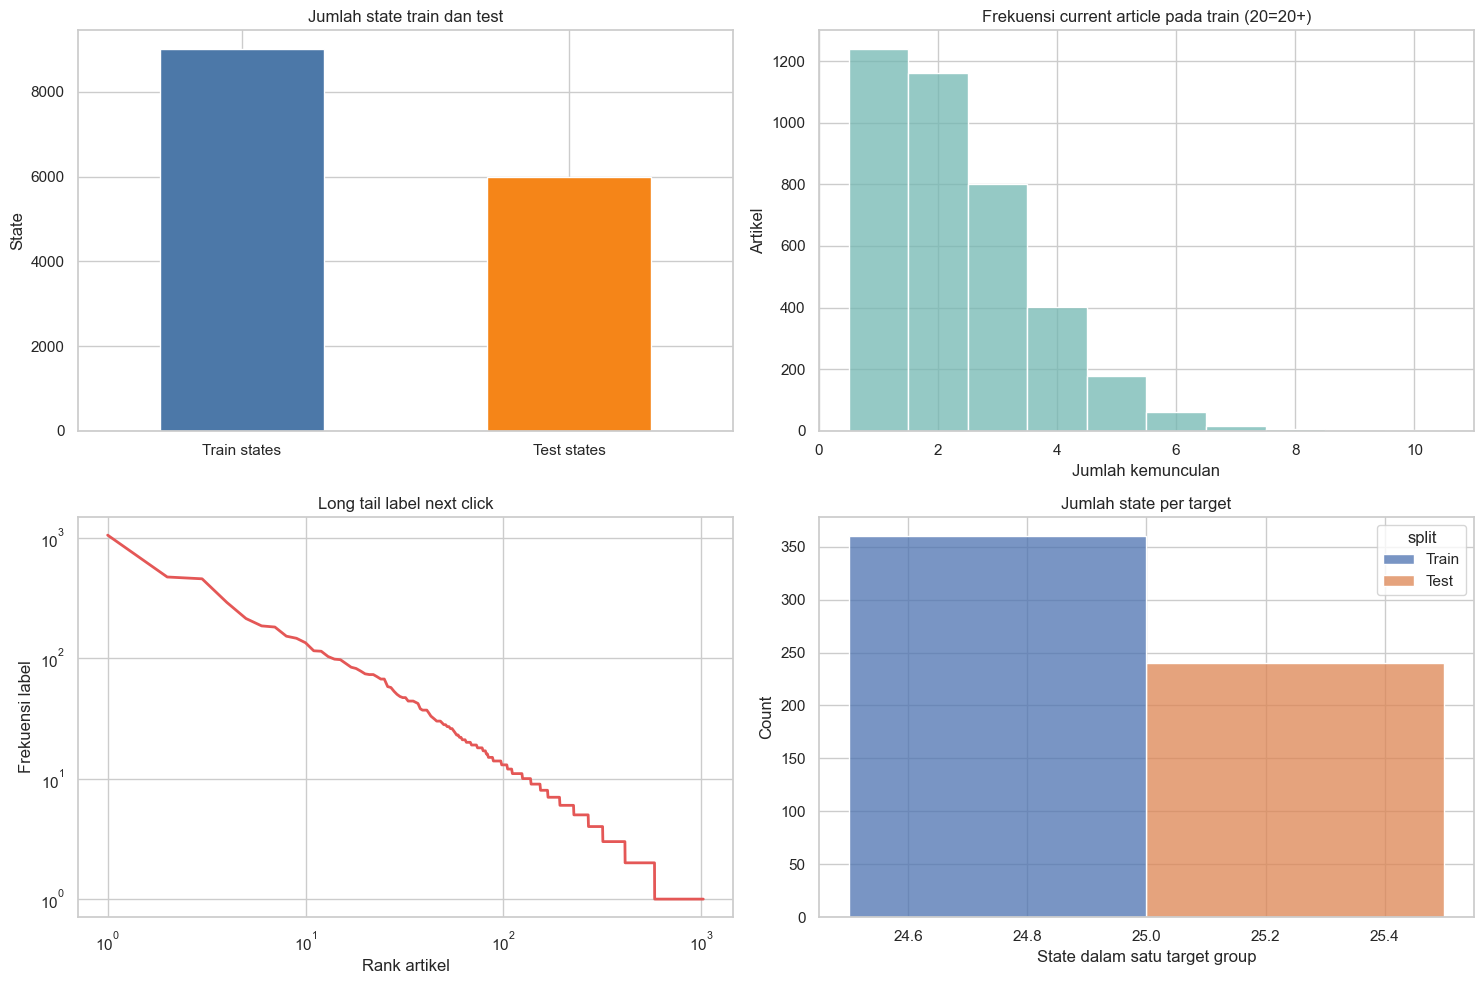

,value
unique_train_targets,360.000000
unique_test_targets,240.000000
target_overlap,0.000000
unique_train_currents,3866.000000
unique_test_currents,3312.000000
unique_next_labels,1023.000000
direct_target_rate,0.007444
top_1_next_label_share,0.116444
top_10_next_label_share,0.363889


In [3]:

train_current_freq=train.current_article_id.value_counts()
next_freq=train.next_article_id.value_counts()
train_target_size=train.groupby('target_article_id').size()
test_target_size=test.groupby('target_article_id').size()
target_overlap=len(set(train.target_article_id)&set(test.target_article_id))

fig,ax=plt.subplots(2,2,figsize=(15,10))
pd.Series({'Train states':len(train),'Test states':len(test)}).plot.bar(
    ax=ax[0,0],color=['#4c78a8','#f58518'],rot=0
)
ax[0,0].set_title('Jumlah state train dan test'); ax[0,0].set_ylabel('State')

sns.histplot(train_current_freq.clip(upper=20),bins=20,discrete=True,ax=ax[0,1],color='#72b7b2')
ax[0,1].set_title('Frekuensi current article pada train (20=20+)')
ax[0,1].set_xlabel('Jumlah kemunculan'); ax[0,1].set_ylabel('Artikel')

rank=np.arange(1,len(next_freq)+1)
ax[1,0].plot(rank,next_freq.to_numpy(),color='#e45756',lw=2)
ax[1,0].set_xscale('log'); ax[1,0].set_yscale('log')
ax[1,0].set_title('Long tail label next click'); ax[1,0].set_xlabel('Rank artikel'); ax[1,0].set_ylabel('Frekuensi label')

target_size_frame=pd.DataFrame({
    'states':pd.concat([train_target_size,test_target_size]).to_numpy(),
    'split':['Train']*len(train_target_size)+['Test']*len(test_target_size),
})
sns.histplot(data=target_size_frame,x='states',hue='split',multiple='dodge',discrete=True,ax=ax[1,1])
ax[1,1].set_title('Jumlah state per target'); ax[1,1].set_xlabel('State dalam satu target group')
plt.tight_layout(); plt.show()

state_eda=pd.Series({
    'unique_train_targets':train.target_article_id.nunique(),
    'unique_test_targets':test.target_article_id.nunique(),
    'target_overlap':target_overlap,
    'unique_train_currents':train.current_article_id.nunique(),
    'unique_test_currents':test.current_article_id.nunique(),
    'unique_next_labels':train.next_article_id.nunique(),
    'direct_target_rate':(train.next_article_id==train.target_article_id).mean(),
    'top_1_next_label_share':next_freq.iloc[0]/len(train),
    'top_10_next_label_share':next_freq.head(10).sum()/len(train),
})
display(state_eda.to_frame('value'))


### Interpretasi EDA State

- Train berisi **9.000 state** dan test berisi **6.000 state**.
- Terdapat **360 target train** dan **240 target test**, masing-masing tepat memiliki 25 state. Tidak ada target yang overlap antara kedua split. Karena itu random row split akan memberi validasi yang terlalu optimistis, sehingga validation wajib dikelompokkan berdasarkan target.
- Train mencakup 3.866 current articles, tetapi hanya **1.023 artikel** pernah menjadi label next click. Distribusinya sangat long tail.
- Satu label terpopuler mencakup sekitar **11,64%** train dan sepuluh label teratas mencakup **36,39%**. Popularity berguna sebagai fitur, tetapi tidak cukup sebagai model karena sebagian besar label jarang muncul.
- Next click langsung menuju target hanya terjadi pada sekitar **0,74%** state. Model harus benar-benar mempelajari routing multi-step, bukan sekadar memilih target ketika tersedia.

## 4. Exploratory Data Analysis Artikel dan Kategori

EDA metadata memeriksa panjang judul, jumlah kategori per artikel, kategori paling umum, serta cakupan article ID pada peran current, target, dan next click.

Analisis ini menentukan bagaimana teks dan kategori sebaiknya direpresentasikan. Judul yang pendek cocok dipadukan dengan character n-gram, sedangkan kategori memberikan konteks tambahan untuk artikel yang namanya ambigu.

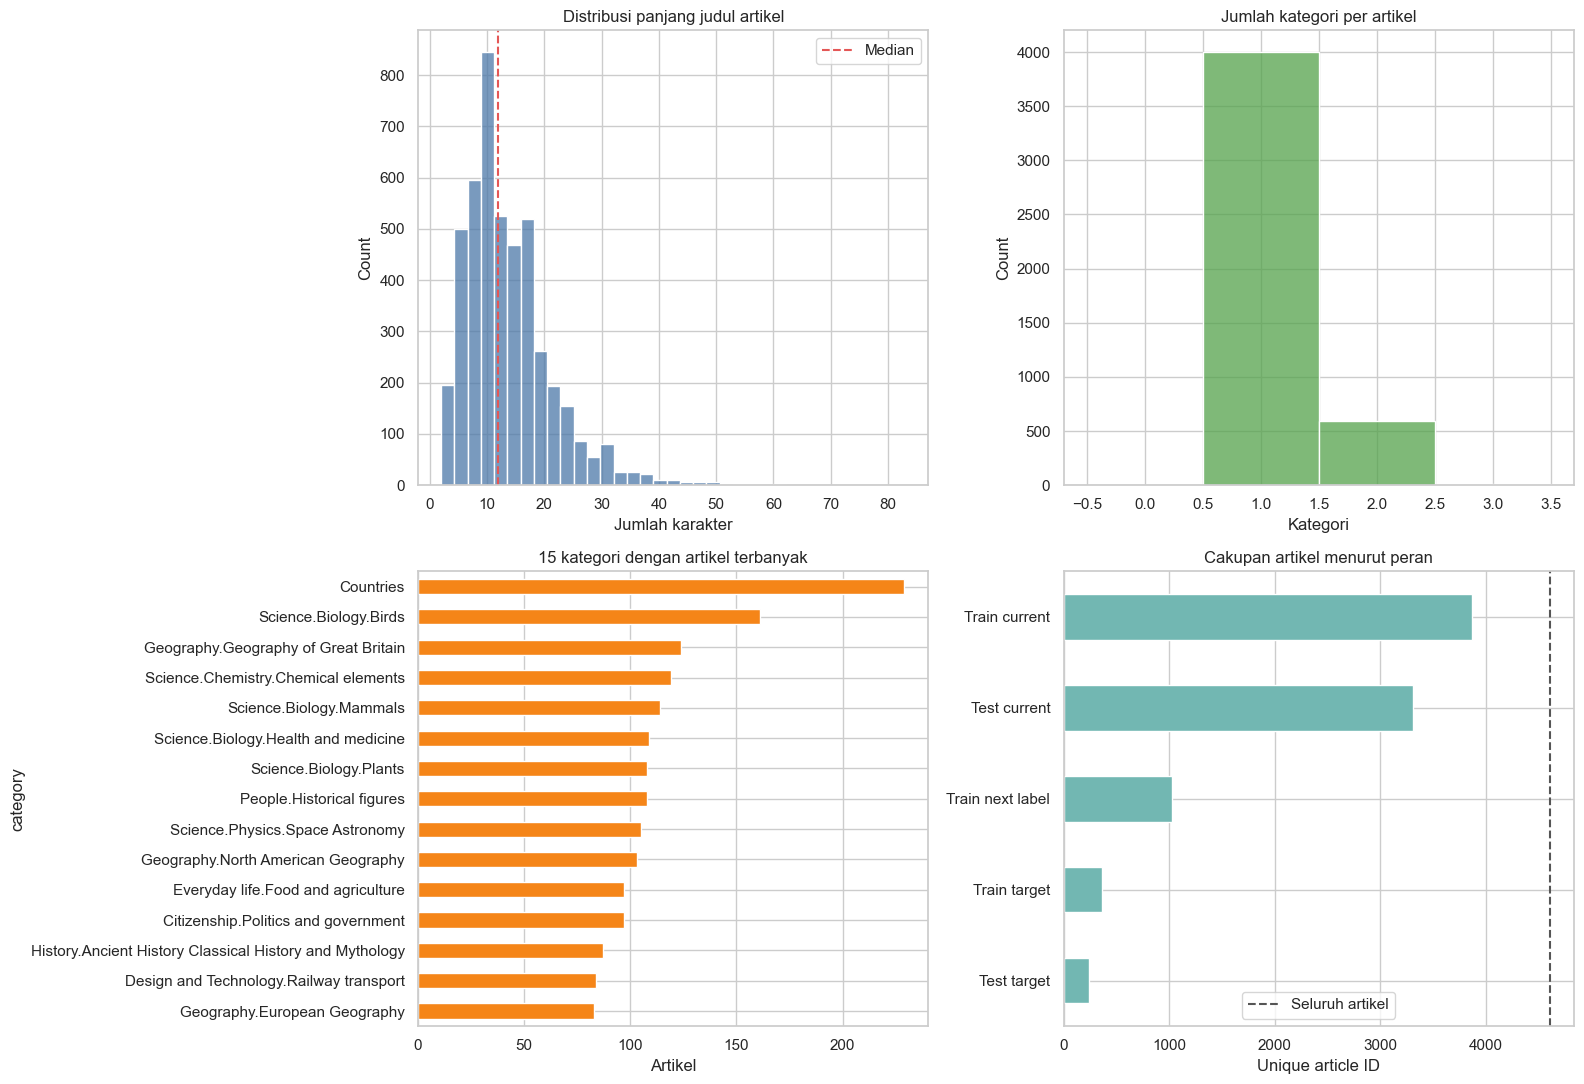

,value
articles,4604.000000
category_rows,5204.000000
unique_categories,129.000000
median_title_length,12.000000
p95_title_length,28.000000
mean_categories_per_article,1.130321
articles_without_category,6.000000


In [4]:

article_eda=articles[['article_id','title']].copy()
article_eda['title_length']=article_eda.title.astype(str).str.len()
categories_per_article=categories.groupby('article_id').size().reindex(articles.article_id,fill_value=0)
top_categories=categories.category.value_counts().head(15).sort_values()
role_coverage=pd.Series({
    'Train current':train.current_article_id.nunique(),
    'Test current':test.current_article_id.nunique(),
    'Train target':train.target_article_id.nunique(),
    'Test target':test.target_article_id.nunique(),
    'Train next label':train.next_article_id.nunique(),
})

fig,ax=plt.subplots(2,2,figsize=(16,11))
sns.histplot(article_eda.title_length,bins=35,ax=ax[0,0],color='#4c78a8')
ax[0,0].axvline(article_eda.title_length.median(),color='#e45756',ls='--',label='Median')
ax[0,0].set_title('Distribusi panjang judul artikel'); ax[0,0].set_xlabel('Jumlah karakter'); ax[0,0].legend()

sns.histplot(categories_per_article,bins=np.arange(-.5,categories_per_article.max()+1.5,1),discrete=True,ax=ax[0,1],color='#54a24b')
ax[0,1].set_title('Jumlah kategori per artikel'); ax[0,1].set_xlabel('Kategori')

top_categories.index=top_categories.index.str.replace('subject.','',regex=False).str.replace('_',' ',regex=False)
top_categories.plot.barh(ax=ax[1,0],color='#f58518')
ax[1,0].set_title('15 kategori dengan artikel terbanyak'); ax[1,0].set_xlabel('Artikel')

role_coverage.sort_values().plot.barh(ax=ax[1,1],color='#72b7b2')
ax[1,1].axvline(len(articles),color='#555555',ls='--',label='Seluruh artikel')
ax[1,1].set_title('Cakupan artikel menurut peran'); ax[1,1].set_xlabel('Unique article ID'); ax[1,1].legend()
plt.tight_layout(); plt.show()

metadata_summary=pd.Series({
    'articles':len(articles),
    'category_rows':len(categories),
    'unique_categories':categories.category.nunique(),
    'median_title_length':article_eda.title_length.median(),
    'p95_title_length':article_eda.title_length.quantile(.95),
    'mean_categories_per_article':categories_per_article.mean(),
    'articles_without_category':int((categories_per_article==0).sum()),
})
display(metadata_summary.to_frame('value'))


### Interpretasi EDA Artikel dan Kategori

- Corpus memuat **4.604 artikel**, 5.204 pasangan article-category, dan 129 kategori unik.
- Median panjang judul hanya **12 karakter**, sedangkan persentil ke-95 adalah 28 karakter. Word TF-IDF perlu dilengkapi character n-gram agar judul pendek, variasi ejaan, dan named entity tetap dapat dibandingkan.
- Rata-rata artikel memiliki **1,13 kategori**, median satu, dan hanya enam artikel tanpa kategori. Kategori cukup lengkap untuk menjadi semantic context tambahan.
- Cakupan next-click label jauh lebih sempit daripada cakupan current article. Temuan ini mendukung penggunaan click popularity sebagai fitur kecil, tetapi target split yang benar-benar terpisah tetap menuntut fitur graph dan semantic yang dapat melakukan generalisasi.

## 5. Preprocessing Link dari Screenshot

Link artikel sebelumnya diekstrak dari teks biru pada screenshot menggunakan deteksi region dan OCR. Cache yang digunakan di sini memuat accepted links serta recovery untuk region OCR yang menggabungkan beberapa judul.

Preprocessing ini menghasilkan directed hyperlink graph tanpa menjalankan OCR ulang. Recovery hanya memetakan teks yang terdeteksi ke artikel resmi dan tidak menggunakan label `next_article_id`.

,value
recovery_source,cached: /Users/timotiuspatrick/Documents/Patri...
recovered_edges,2162
total_graph_edges,95418


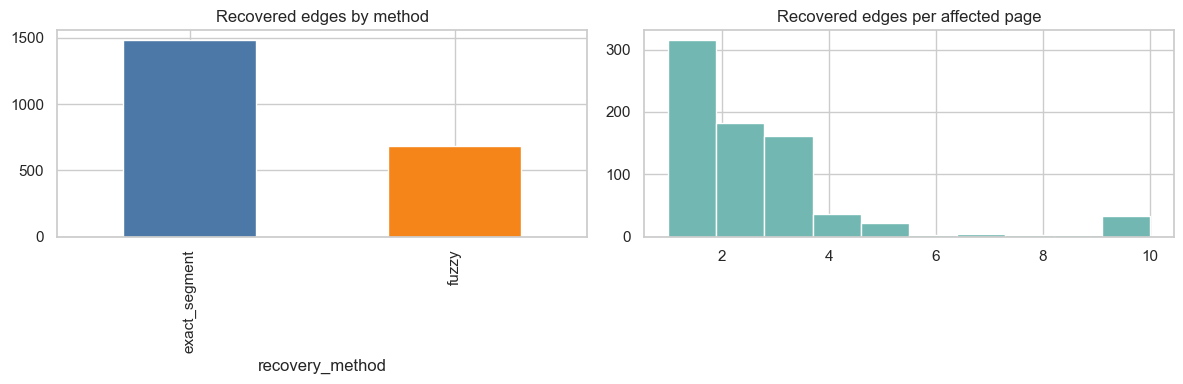

INSIGHT RECOVERY: using cached: /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/reports/datathon_task2_v3_recovered_edges.csv; OCR engine is not rerun.


In [5]:
import re
from rapidfuzz import fuzz, process

def normalize_ocr_text(value):
    return re.sub(r'[^a-z0-9]+',' ',str(value).casefold()).strip()

# Prefer the persisted V3 result. This avoids repeating OCR-region recovery on
# every local run and also works when a previous output bundle is attached to Kaggle.
recovery_candidates = [LOCAL_PATRICK_PATH/'reports/datathon_task2_v3_recovered_edges.csv']
if IS_KAGGLE:
    recovery_candidates += list(Path('/kaggle/input').glob('**/datathon_task2_v3_recovered_edges.csv'))
RECOVERY_CACHE = next((p for p in recovery_candidates if p.exists()), None)

if RECOVERY_CACHE is not None:
    recovery = pd.read_csv(RECOVERY_CACHE)
    required = {'source_id','candidate_id','ocr_text','position_y','ocr_confidence','recovery_method'}
    assert required.issubset(recovery.columns), f'Recovery cache missing: {required-set(recovery.columns)}'
    recovery['match_score'] = recovery.get('match_score', 1.0)
    suspect_regions = raw_ocr.iloc[0:0].copy()
    recovery_source = f'cached: {RECOVERY_CACHE}'
else:
    title_map=articles.set_index('article_id').title.to_dict()
    normalized_titles={aid:normalize_ocr_text(title) for aid,title in title_map.items()}
    title_choices={aid:value for aid,value in normalized_titles.items() if len(value)>=4}
    candidate_title_len=raw_ocr.candidate_title.fillna('').astype(str).str.len()
    ocr_text_len=raw_ocr.ocr_text.fillna('').astype(str).str.len()
    suspect_regions=raw_ocr[(raw_ocr.status.ne('accepted'))|(ocr_text_len>candidate_title_len+3)].copy()
    recovery_rows=[]
    for row in suspect_regions.itertuples(index=False):
        text=normalize_ocr_text(row.ocr_text)
        if not text: continue
        padded=f' {text} '; found=set()
        for article_id,title_norm in title_choices.items():
            if f' {title_norm} ' in padded: found.add(int(article_id))
        method='exact_segment'
        if not found:
            method='fuzzy'
            for _,score,article_id in process.extract(text,title_choices,scorer=fuzz.WRatio,limit=3,score_cutoff=90):
                found.add(int(article_id))
            if text.startswith('l'):
                variant='i'+text[1:]
                for _,score,article_id in process.extract(variant,title_choices,scorer=fuzz.WRatio,limit=2,score_cutoff=94):
                    found.add(int(article_id))
        for article_id in found:
            if article_id==int(row.source_id): continue
            actual_method='exact_segment' if f' {normalized_titles[article_id]} ' in padded else method
            recovery_rows.append({'source_id':int(row.source_id),'candidate_id':article_id,'ocr_text':str(row.ocr_text),'position_y':float(row.position_y),'box_x':float(row.box_x),'ocr_confidence':float(row.ocr_confidence),'match_score':1.0,'recovery_method':actual_method})
    recovery=pd.DataFrame(recovery_rows).drop_duplicates(['source_id','candidate_id'])
    existing_edges=set(map(tuple,links[['source_id','candidate_id']].astype(int).to_numpy()))
    recovery=recovery[[tuple(x) not in existing_edges for x in recovery[['source_id','candidate_id']].to_numpy()]].reset_index(drop=True)
    recovery_source='computed fallback from raw OCR cache'

for column in links.columns:
    if column not in recovery.columns:
        recovery[column] = 1.0 if column == 'match_score' else 0.0
links_v3=pd.concat([links,recovery[links.columns]],ignore_index=True)
links_v3=links_v3.sort_values(['source_id','candidate_id','match_score','ocr_confidence'],ascending=[True,True,False,False]).drop_duplicates(['source_id','candidate_id']).reset_index(drop=True)
display(pd.Series({'recovery_source':recovery_source,'recovered_edges':len(recovery),'total_graph_edges':len(links_v3)}).to_frame('value'))
fig,ax=plt.subplots(1,2,figsize=(12,4))
recovery.recovery_method.value_counts().plot.bar(ax=ax[0],color=['#4c78a8','#f58518']); ax[0].set_title('Recovered edges by method')
recovery.groupby('source_id').size().clip(upper=10).hist(ax=ax[1],bins=10,color='#72b7b2'); ax[1].set_title('Recovered edges per affected page')
plt.tight_layout(); plt.show()
print(f'INSIGHT RECOVERY: using {recovery_source}; OCR engine is not rerun.')

## 6. Exploratory Data Analysis Graph dan Kualitas Kandidat

Setiap artikel menjadi node dan setiap link biru menjadi directed edge. Analisis memeriksa distribusi out-degree, cakupan halaman, posisi link, confidence OCR, dan jumlah edge hasil recovery.

Graph akhir memiliki candidate coverage yang sangat tinggi. Pada run tersimpan, jawaban benar tersedia dalam candidate pool untuk **99,39%** state, sehingga bottleneck utama berada pada pemilihan satu link di antara beberapa kandidat, bukan pada ekstraksi gambar.

In [6]:
n_articles = int(articles.article_id.max()) + 1
titles = articles.set_index('article_id').title.to_dict()
ocr_candidates = defaultdict(set)
for r in links_v3.itertuples(index=False):
    ocr_candidates[int(r.source_id)].add(int(r.candidate_id))

accepted_raw = raw_ocr[raw_ocr.status.eq('accepted') & raw_ocr.candidate_id.notna()].copy()
accepted_raw['candidate_id'] = accepted_raw.candidate_id.astype(int)
raw_agg = accepted_raw.groupby(['source_id','candidate_id']).agg(
    ocr_conf_max=('ocr_confidence','max'), ocr_conf_mean=('ocr_confidence','mean'),
    title_match_max=('match_score','max'), first_position=('position_y','min'),
    mention_count=('candidate_id','size')
).reset_index()
raw_meta = {
    (int(r.source_id),int(r.candidate_id)):(float(r.ocr_conf_max),float(r.ocr_conf_mean),float(r.title_match_max),float(r.first_position),int(r.mention_count))
    for r in raw_agg.itertuples(index=False)
}

for r in recovery.itertuples(index=False):
    raw_meta[(int(r.source_id),int(r.candidate_id))]=(float(r.ocr_confidence),float(r.ocr_confidence),1.0,float(r.position_y),1)

out_degree = np.zeros(n_articles,dtype=np.int32)
in_degree = np.zeros(n_articles,dtype=np.int32)
reverse_adj = [[] for _ in range(n_articles)]
incoming_sets = [set() for _ in range(n_articles)]
for source,candidates in ocr_candidates.items():
    out_degree[source] = len(candidates)
    for candidate in candidates:
        in_degree[candidate] += 1
        reverse_adj[candidate].append(source)
        incoming_sets[candidate].add(source)

graph_summary = pd.Series({
    'directed_edges':int(out_degree.sum()),
    'pages_with_links':int((out_degree>0).sum()),
    'pages_without_links':int((out_degree==0).sum()),
    'median_out_degree':float(np.median(out_degree[out_degree>0])),
    'p95_out_degree':float(np.percentile(out_degree[out_degree>0],95)),
})
display(graph_summary.to_frame('value'))

,value
directed_edges,95418.00
pages_with_links,4546.00
pages_without_links,58.00
median_out_degree,16.00
p95_out_degree,54.75


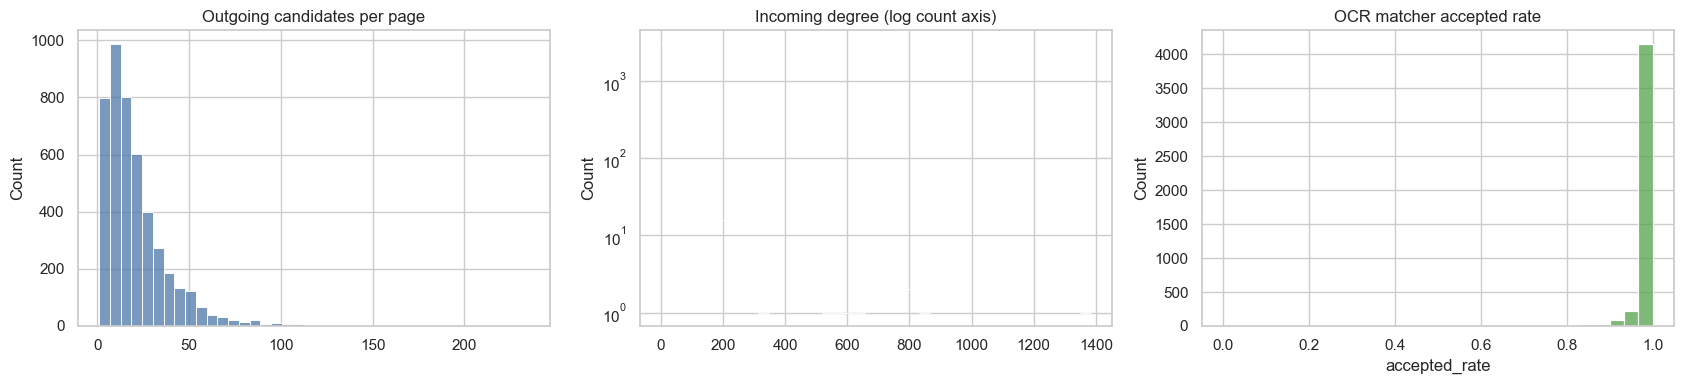

,source_id,regions,accepted_links,accepted_rate,mean_ocr_confidence,mean_match_score
1556,1577,1,0,0.000000,0.840000,0.000000
499,508,6,2,0.333333,0.934167,0.435307
273,277,7,3,0.428571,0.896429,0.642010
1827,1851,2,1,0.500000,0.960000,0.916667
1920,1945,2,1,0.500000,0.930000,0.500000
3162,3204,2,1,0.500000,0.947500,0.833333
3649,3695,2,1,0.500000,0.867500,0.500000
3892,3941,2,1,0.500000,0.957500,0.851351
3953,4002,8,4,0.500000,0.885042,0.683770
539,549,3,2,0.666667,0.956667,0.888889


INSIGHT GRAPH: candidate cap 100 mempertahankan hampir seluruh page, sedangkan long-tail degree mencegah pair table membesar tanpa batas.


In [7]:
fig, ax = plt.subplots(1,3,figsize=(17,4))
sns.histplot(out_degree[out_degree>0],bins=40,ax=ax[0],color='#4c78a8'); ax[0].set_title('Outgoing candidates per page')
sns.histplot(in_degree[in_degree>0],bins=40,ax=ax[1],color='#f58518',log_scale=(False,True)); ax[1].set_title('Incoming degree (log count axis)')
sns.histplot(quality.accepted_rate,bins=30,ax=ax[2],color='#54a24b'); ax[2].set_title('OCR matcher accepted rate')
plt.tight_layout(); plt.show()

low_quality = quality.sort_values(['accepted_rate','regions']).head(12)
display(low_quality)
print('INSIGHT GRAPH: candidate cap 100 mempertahankan hampir seluruh page, sedangkan long-tail degree mencegah pair table membesar tanpa batas.')

### Interpretasi EDA OCR dan Hyperlink Graph

- Graph hasil OCR dan recovery memiliki **95.418 directed edges**. Sebanyak 4.546 dari 4.604 halaman memiliki outgoing link, sedangkan 58 halaman tidak menghasilkan kandidat.
- Median out-degree adalah **16** dan persentil ke-95 sekitar **55**. Distribusi degree memiliki long tail, sehingga candidate cap diperlukan untuk menjaga ukuran pair table tetap terkendali.
- Mean OCR matcher accepted rate adalah **99,05%** dan mediannya 100%. Angka ini menunjukkan keberhasilan mapping pada region yang terdeteksi, bukan precision terhadap seluruh link asli.
- Recovery menambahkan 1.482 exact-segment edges dan 680 fuzzy edges. Dengan candidate recall akhir 99,39%, OCR cukup kuat untuk dipakai sebagai preprocessing reusable dan tidak perlu dijalankan ulang ketika model direrun.

## 7. Representasi Teks, Kategori, dan Jarak Graph

Judul artikel direpresentasikan menggunakan word dan character TF-IDF, sementara kategori diolah menjadi exact overlap dan token overlap. Reverse BFS dari target menghitung jarak seluruh artikel menuju target secara efisien.

Hasil EDA route menunjukkan **96,93%** label train berada pada kandidat dengan jarak graph minimum. Namun hanya **28,12%** state memiliki satu kandidat minimum yang unik, sehingga diperlukan tie-breaking berbasis struktur dan semantik.

In [8]:
category_lists = categories.groupby('article_id').category.apply(list).to_dict()
category_sets = {i:set(category_lists.get(i,[])) for i in range(n_articles)}
category_tokens = {
    i:set(token.lower() for cat in category_lists.get(i,[]) for token in str(cat).replace('subject.','').replace('.',' ').replace('_',' ').split())
    for i in range(n_articles)
}
category_prefixes = {}
for aid in range(n_articles):
    prefixes=set()
    for category in category_lists.get(aid,[]):
        parts=str(category).split('.')
        prefixes.update('.'.join(parts[:depth]) for depth in range(2,len(parts)+1))
    category_prefixes[aid]=prefixes

docs=[]
for aid in range(n_articles):
    cat_doc=' '.join(str(x).replace('subject.',' ').replace('.',' ').replace('_',' ') for x in category_lists.get(aid,[]))
    docs.append(f'{titles[aid]} {titles[aid]} {cat_doc}')
word_x=TfidfVectorizer(ngram_range=(1,2),sublinear_tf=True).fit_transform(docs)
char_x=TfidfVectorizer(analyzer='char_wb',ngram_range=(2,5),min_df=2,sublinear_tf=True,max_features=30000).fit_transform(docs)
print('Word TF-IDF:',word_x.shape,'| Char TF-IDF:',char_x.shape)

Word TF-IDF: (4604, 17739) | Char TF-IDF: (4604, 17951)


In [9]:
dist_cache={}
def distances_to_target(target):
    target=int(target)
    if target in dist_cache: return dist_cache[target]
    dist=np.full(n_articles,99,dtype=np.int16); dist[target]=0
    queue=deque([target])
    while queue:
        node=queue.popleft(); nd=int(dist[node])+1
        for previous in reverse_adj[node]:
            if dist[previous]==99:
                dist[previous]=nd; queue.append(previous)
    dist_cache[target]=dist
    return dist

def sparse_cosine(matrix,candidates,target):
    return np.asarray(matrix[candidates].multiply(matrix[int(target)]).sum(axis=1)).ravel().astype(np.float32)

def jaccard(a,b):
    return len(a&b)/len(a|b) if (a or b) else 0.0

def fit_priors(frame):
    global_counts=Counter(frame.next_article_id.astype(int))
    current_counts=defaultdict(Counter)
    for r in frame.itertuples(index=False): current_counts[int(r.current_article_id)][int(r.next_article_id)]+=1
    return global_counts,current_counts,[x for x,_ in global_counts.most_common(30)]

## 8. Candidate-Pair Features dan Grouped Validation

Satu baris modeling mewakili pasangan `(state, candidate)`. Candidate pool berasal dari outgoing links halaman saat ini, kemudian setiap pasangan diberi fitur jarak, perubahan jarak, kemiripan teks, overlap kategori, degree, posisi link, click prior yang fold-safe, dan struktur neighborhood.

`GroupKFold(target_article_id)` digunakan agar seluruh state dengan target yang sama selalu berada pada fold yang sama. Ini mengukur kemampuan model melakukan generalisasi ke target baru seperti pada test set.

In [10]:
FEATURES=[
 'direct_target','word_cosine','char_cosine','category_exact_jaccard','category_token_jaccard',
 'graph_distance','graph_improvement','on_shortest_path','is_min_neighbor_distance','distance_tie_count',
 'ocr_conf_max','ocr_conf_mean','title_match_max','first_position','log_mentions','log_global_clicks',
 'log_current_clicks','observed_edge','log_out_degree','log_in_degree','word_rank','char_rank','position_rank',
 'distance_rank','category_overlap_count','category_prefix_jaccard','out_neighbor_jaccard',
 'in_neighbor_jaccard','reciprocal_link'
]

def build_pairs(frame,priors,training=False):
    global_counts,current_counts,global_top=priors
    blocks=[]; labels=[]; states=[]; candidates_out=[]
    has_label='next_article_id' in frame.columns
    for row in frame.itertuples(index=False):
        state,current,target=int(row.state_id),int(row.current_article_id),int(row.target_article_id)
        truth=int(row.next_article_id) if has_label else None
        observed=set(current_counts.get(current,{}))
        candidates=set(ocr_candidates.get(current,set()))|observed
        if not candidates: candidates=set(global_top[:20])|{target}
        if training and truth is not None: candidates.add(truth)
        def priority(candidate):
            conf,_,match,position,mentions=raw_meta.get((current,candidate),(0,0,0,1,0))
            return candidate==truth,candidate==target,candidate in observed,match,conf,mentions,-position
        candidate_list=sorted(candidates,key=priority,reverse=True)[:MAX_CANDIDATES]
        cands=np.asarray(candidate_list,dtype=int)
        dist=distances_to_target(target); cdist=np.minimum(dist[cands].astype(np.float32),20)
        current_dist=min(int(dist[current]),20); min_dist=float(cdist.min()); tie_count=int((cdist==min_dist).sum())
        word=sparse_cosine(word_x,cands,target); char=sparse_cosine(char_x,cands,target)
        positions=np.asarray([raw_meta.get((current,int(c)),(0,0,0,1,0))[3] for c in cands],dtype=np.float32)
        block=np.zeros((len(cands),len(FEATURES)),dtype=np.float32)
        for idx,candidate in enumerate(cands):
            candidate=int(candidate); conf_max,conf_mean,match,position,mentions=raw_meta.get((current,candidate),(0,0,0,1,0))
            global_count=global_counts.get(candidate,0); current_count=current_counts.get(current,{}).get(candidate,0)
            if training and truth is not None and candidate==truth:
                global_count=max(0,global_count-1); current_count=max(0,current_count-1)
            block[idx,:20]=[
                candidate==target,word[idx],char[idx],jaccard(category_sets[candidate],category_sets[target]),
                jaccard(category_tokens[candidate],category_tokens[target]),cdist[idx],current_dist-cdist[idx],
                int(current_dist<20 and cdist[idx]+1==current_dist),cdist[idx]==min_dist,tie_count,
                conf_max,conf_mean,match,position,math.log1p(mentions),math.log1p(global_count),
                math.log1p(current_count),current_count>0,math.log1p(out_degree[candidate]),math.log1p(in_degree[candidate])]
            block[idx,24:]=[
                len(category_sets[candidate]&category_sets[target]),jaccard(category_prefixes[candidate],category_prefixes[target]),
                jaccard(ocr_candidates.get(candidate,set()),ocr_candidates.get(target,set())),
                jaccard(incoming_sets[candidate],incoming_sets[target]),candidate in ocr_candidates.get(target,set())]
        block[:,20]=pd.Series(word).rank(method='average',pct=True).to_numpy(np.float32)
        block[:,21]=pd.Series(char).rank(method='average',pct=True).to_numpy(np.float32)
        block[:,22]=pd.Series(-positions).rank(method='average',pct=True).to_numpy(np.float32)
        block[:,23]=pd.Series(-cdist).rank(method='average',pct=True).to_numpy(np.float32)
        blocks.append(block); labels.extend((cands==truth).astype(np.int8) if truth is not None else np.zeros(len(cands),dtype=np.int8))
        states.extend([state]*len(cands)); candidates_out.extend(cands.tolist())
    return np.vstack(blocks),np.asarray(labels,np.int8),np.asarray(states,np.int32),np.asarray(candidates_out,np.int32)

def evaluate_scores(y,states,candidates,scores):
    order=np.lexsort((candidates,-scores,states)); sorted_states=states[order]
    first=np.r_[True,sorted_states[1:]!=sorted_states[:-1]]; winners=order[first]
    ranked=pd.DataFrame({'state':states,'candidate':candidates,'truth':y,'score':scores}).sort_values(['state','score','candidate'],ascending=[True,False,True])
    ranked['rank']=ranked.groupby('state').cumcount()+1
    n_states=len(np.unique(states))
    return {
        'accuracy':float(y[winners].mean()),
        'top3':float(((ranked.truth==1)&(ranked['rank']<=3)).groupby(ranked.state).max().sum()/n_states),
        'top5':float(((ranked.truth==1)&(ranked['rank']<=5)).groupby(ranked.state).max().sum()/n_states),
        'candidate_recall':float(y.sum()/n_states),
    }

def winner_table(y,states,candidates,scores):
    order=np.lexsort((candidates,-scores,states)); sorted_states=states[order]
    first=np.r_[True,sorted_states[1:]!=sorted_states[:-1]]; idx=order[first]
    return pd.DataFrame({'state_id':states[idx],'prediction':candidates[idx],'correct':y[idx].astype(bool),'score':scores[idx]})

Fold 0: train pairs=128,296 | val pairs=64,363


Fold 1: train pairs=128,156 | val pairs=64,502


Fold 2: train pairs=128,886 | val pairs=63,757


,fold,candidate_recall,truth_is_min_distance,truth_is_unique_min,states_unique_min
0,0,0.994000,0.981000,0.273667,0.285000
1,1,0.994333,0.959667,0.261000,0.283333
2,2,0.993333,0.967333,0.255667,0.275333


,mean
fold,1.000000
candidate_recall,0.993889
truth_is_min_distance,0.969333
truth_is_unique_min,0.263444
states_unique_min,0.281222


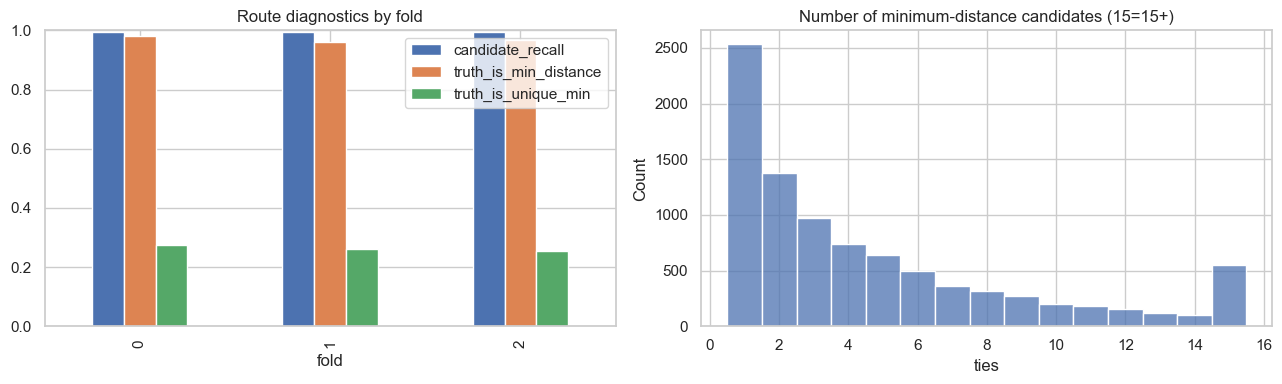

INSIGHT ROUTE: 96.93% truth berada di minimum distance, tetapi hanya 28.12% state memiliki minimum yang unik.


In [11]:
fold_cache=[]; route_rows=[]
splitter=GroupKFold(n_splits=N_SPLITS)
for fold,(fit_idx,val_idx) in enumerate(splitter.split(dev_train,groups=dev_train.target_article_id)):
    fit=dev_train.iloc[fit_idx].copy(); val=dev_train.iloc[val_idx].copy(); priors=fit_priors(fit)
    x_fit,y_fit,q_fit,c_fit=build_pairs(fit,priors,training=True)
    x_val,y_val,q_val,c_val=build_pairs(val,priors,training=False)
    state_count=len(np.unique(q_val)); positive=y_val==1
    tie_idx=FEATURES.index('distance_tie_count'); min_idx=FEATURES.index('is_min_neighbor_distance')
    state_ties=pd.DataFrame({'state':q_val,'ties':x_val[:,tie_idx]}).drop_duplicates('state')
    route_rows.append({
        'fold':fold,'candidate_recall':positive.sum()/state_count,
        'truth_is_min_distance':(positive&(x_val[:,min_idx]==1)).sum()/state_count,
        'truth_is_unique_min':(positive&(x_val[:,min_idx]==1)&(x_val[:,tie_idx]==1)).sum()/state_count,
        'states_unique_min':state_ties.ties.eq(1).mean(),
    })
    fold_cache.append({'fold':fold,'fit':(x_fit,y_fit,q_fit,c_fit),'val':(x_val,y_val,q_val,c_val)})
    print(f'Fold {fold}: train pairs={len(x_fit):,} | val pairs={len(x_val):,}')

route_df=pd.DataFrame(route_rows)
display(route_df); display(route_df.mean(numeric_only=True).to_frame('mean'))
fig,ax=plt.subplots(1,2,figsize=(13,4))
route_df.set_index('fold')[['candidate_recall','truth_is_min_distance','truth_is_unique_min']].plot.bar(ax=ax[0]); ax[0].set_ylim(0,1); ax[0].set_title('Route diagnostics by fold')
all_ties=pd.concat([pd.DataFrame({'state':f['val'][2],'ties':f['val'][0][:,FEATURES.index('distance_tie_count')]}) for f in fold_cache]).drop_duplicates('state')
sns.histplot(all_ties.ties.clip(upper=15),bins=15,discrete=True,ax=ax[1]); ax[1].set_title('Number of minimum-distance candidates (15=15+)')
plt.tight_layout(); plt.show()
print(f"INSIGHT ROUTE: {route_df.truth_is_min_distance.mean():.2%} truth berada di minimum distance, tetapi hanya {route_df.states_unique_min.mean():.2%} state memiliki minimum yang unik.")

### Interpretasi EDA Routing

- Jawaban benar tersedia dalam candidate pool untuk **99,39%** validation states.
- Sebanyak **96,93%** jawaban berada pada kandidat dengan graph distance minimum menuju target. Ini menjadikan reverse BFS sebagai anchor yang sangat kuat.
- Hanya **28,12%** state mempunyai satu kandidat minimum yang unik. Sebagian besar state membutuhkan tie-breaking di antara beberapa shortest-path candidates.
- Histogram tie size menunjukkan bahwa masalah utama bukan menemukan rute yang dapat mencapai target, melainkan memilih rute yang paling mungkin dipilih navigator. Karena itu model final menambahkan shortest-path mass, semantic pair features, dan discounted reachability.

## 9. Skor Dasar Berbasis Shortest-Path Structure

Komponen graph memberi prioritas kuat kepada kandidat yang meminimalkan jarak menuju target. Ketika beberapa kandidat sama-sama minimum, skor tambahan menggunakan kemiripan judul/kategori, degree, link position, neighborhood overlap, dan **shortest-path mass**.

Shortest-path mass menghitung jumlah rute terpendek yang dapat dilanjutkan dari setiap kandidat. Transformasi log digunakan agar halaman dengan jumlah rute sangat besar tidak mendominasi skor.

In [12]:
V3_HARDMIN = {
    'is_min_neighbor_distance':100.0,
    'category_exact_jaccard':1.51797340143258,
    'category_overlap_count':0.48994969864263294,
    'category_prefix_jaccard':0.02857276307887291,
    'log_global_clicks':0.02119646682476861,
    'log_in_degree':0.4340986164482358,
    'out_neighbor_jaccard':0.9794117699297289,
    'in_neighbor_jaccard':0.2994440985929203,
    'char_cosine':0.35850562724901813,
    'word_cosine':0.1653051475375229,
    'position_rank':0.04515262127215465,
}
V3_FEATURES=list(V3_HARDMIN)
V3_WEIGHTS=np.asarray([V3_HARDMIN[x] for x in V3_FEATURES],np.float32)
path_count_cache={}
def log_shortest_path_count_to_target(target):
    target=int(target)
    if target in path_count_cache: return path_count_cache[target]
    dist=distances_to_target(target); finite=dist<99
    counts=np.zeros(n_articles,dtype=np.float64); counts[target]=1.0
    max_distance=int(dist[finite].max()) if finite.any() else 0
    for depth in range(1,max_distance+1):
        for node in np.flatnonzero(dist==depth):
            children=np.fromiter(ocr_candidates.get(int(node),()),dtype=np.int32)
            if children.size:
                shortest=children[dist[children]==depth-1]
                if shortest.size: counts[node]=min(1e12,counts[shortest].sum())
    result=np.log1p(counts).astype(np.float32)
    path_count_cache[target]=result
    return result

state_target=train.set_index('state_id').target_article_id.to_dict()
def path_feature_for_pairs(qids,candidates,target_lookup=state_target):
    result=np.zeros(len(qids),dtype=np.float32)
    state_frame=pd.DataFrame({'row':np.arange(len(qids)),'state_id':qids.astype(int),'candidate':candidates.astype(int)})
    state_frame['target']=state_frame.state_id.map(target_lookup).astype(int)
    for target,group in state_frame.groupby('target',sort=False):
        result[group.row.to_numpy()]=log_shortest_path_count_to_target(int(target))[group.candidate.to_numpy(int)]
    return result

display(pd.Series({'locked_v3_features':len(V3_FEATURES),'cached_targets_initially':len(path_count_cache),'path_count_cap':1e12}).to_frame('value'))
print('INSIGHT FEATURE: path mass hanya membedakan route structure; minimum-distance constraint V3 tetap dominan.')

,value
locked_v3_features,1.100000e+01
cached_targets_initially,0.000000e+00
path_count_cap,1.000000e+12


INSIGHT FEATURE: path mass hanya membedakan route structure; minimum-distance constraint V3 tetap dominan.


## 10. Dasar Pemilihan Metode

Dataset memiliki karakteristik Wikispeedia: navigator cenderung bergerak menuju halaman hub pada fase awal dan menggunakan kedekatan isi ketika mendekati target. Karena itu metode final tidak memperlakukan screenshot sebagai klasifikasi gambar langsung.

Screenshot digunakan untuk memperoleh daftar aksi yang sah, graph digunakan untuk perencanaan rute, dan representasi teks digunakan untuk membedakan kandidat yang secara struktural setara. External navigation paths tidak digunakan sebagai label train maupun lookup submission.

## 11. Pretrained Article Embeddings

Setiap artikel direpresentasikan oleh embedding 384 dimensi dari `all-MiniLM-L6-v2` berdasarkan judul dan kategori. Embedding dinormalisasi, disimpan sebagai cache, kemudian direduksi menjadi 48 komponen menggunakan PCA yang di-fit pada seluruh corpus artikel tanpa label.

Cache membuat notebook dapat dijalankan ulang dengan cepat: model pretrained tidak perlu melakukan encoding ulang selama file embedding tersedia.

In [13]:
EMBEDDING_NAME='datathon_task2_v5_minilm_article_embeddings.npz'
embedding_candidates=[OUTPUT_DIR/EMBEDDING_NAME,LOCAL_PATRICK_PATH/'output/v5'/EMBEDDING_NAME]
if IS_KAGGLE:
    embedding_candidates += list(Path('/kaggle/input').glob(f'**/{EMBEDDING_NAME}'))
EMBEDDING_PATH=next((p for p in embedding_candidates if p.exists()),None)
if EMBEDDING_PATH is None:
    raise FileNotFoundError(f'Attach V5 reusable bundle containing {EMBEDDING_NAME}. No model download is required when cache is attached.')
article_embedding=np.load(EMBEDDING_PATH)['embeddings'].astype(np.float32)
assert article_embedding.shape==(n_articles,384)
article_embedding/=np.maximum(np.linalg.norm(article_embedding,axis=1,keepdims=True),1e-8)
from sklearn.decomposition import PCA
pca=PCA(n_components=48,whiten=True,random_state=SEED)
embedding_pca=pca.fit_transform(article_embedding).astype(np.float32)
embedding_pca/=np.maximum(np.linalg.norm(embedding_pca,axis=1,keepdims=True),1e-8)
display(pd.Series({'embedding_path':str(EMBEDDING_PATH),'articles':len(article_embedding),'original_dimensions':384,'pair_ranker_dimensions':48,'pca_explained_variance':pca.explained_variance_ratio_.sum()}).to_frame('value'))
print('INSIGHT CACHE: pretrained encoder inference is skipped; only cached vectors and CPU PCA are used.')

,value
embedding_path,/Users/timotiuspatrick/Documents/Patrick/Kulia...
articles,4604
original_dimensions,384
pair_ranker_dimensions,48
pca_explained_variance,0.674197


INSIGHT CACHE: pretrained encoder inference is skipped; only cached vectors and CPU PCA are used.


## 12. Semantic Candidate-Target Interaction

Model tidak hanya memakai cosine similarity. Untuk setiap kandidat dan target, dibuat fitur nonlinear berupa elementwise product, absolute difference, koordinat PCA kandidat/target, serta directional semantic progress dari current menuju target.

Fitur embedding digabungkan dengan fitur graph, OCR, kategori, dan click prior. LightGBM kemudian mempelajari probability bahwa suatu candidate merupakan next click. Sample weight diseimbangkan per state agar halaman dengan banyak link tidak mendominasi training.

In [14]:
TABULAR=['word_cosine','char_cosine','category_exact_jaccard','category_token_jaccard','log_global_clicks','log_current_clicks','log_in_degree','log_out_degree','word_rank','char_rank','position_rank','category_overlap_count','category_prefix_jaccard','out_neighbor_jaccard','in_neighbor_jaccard','reciprocal_link']
TABULAR_INDEX=[FEATURES.index(name) for name in TABULAR]
MIN_INDEX=FEATURES.index('is_min_neighbor_distance')
TRAIN_LOOKUP=train.set_index('state_id')[['current_article_id','target_article_id']]
TEST_LOOKUP=test.set_index('state_id')[['current_article_id','target_article_id']]
def pair_embedding_features(qids,candidates,lookup):
    frame=pd.DataFrame({'state_id':qids.astype(int),'candidate':candidates.astype(int)}).join(lookup,on='state_id')
    candidate=embedding_pca[frame.candidate.to_numpy(int)]; target=embedding_pca[frame.target_article_id.to_numpy(int)]; current=embedding_pca[frame.current_article_id.to_numpy(int)]
    product=candidate*target; absolute=np.abs(candidate-target); direction=candidate-current; target_direction=target-current
    scalar=np.column_stack([np.sum(candidate*target,axis=1),np.sum(candidate*current,axis=1),np.sum(current*target,axis=1),np.sum(direction*target_direction,axis=1),np.linalg.norm(target_direction,axis=1)-np.linalg.norm(target-candidate,axis=1)]).astype(np.float32)
    return np.column_stack([product,absolute,candidate,target,scalar]).astype(np.float32)
def query_rank(values,qids):
    return pd.DataFrame({'value':values,'qid':qids}).groupby('qid').value.rank(pct=True,method='average').to_numpy(np.float32)
PARAMS=[
 {'num_leaves':7,'min_child_samples':30,'reg_lambda':8.0},
 {'num_leaves':15,'min_child_samples':30,'reg_lambda':10.0},
 {'num_leaves':15,'min_child_samples':60,'reg_lambda':15.0},
 {'num_leaves':31,'min_child_samples':50,'reg_lambda':20.0},
]
BETAS=[0.0,.05,.1,.2,.3,.5,.8,1.2,2.0]
LOCKED_CONFIG=3; LOCKED_BETA=.20

## 13. Out-of-Fold Training Semantic Ranker

LightGBM dilatih pada minimum-distance candidates yang memiliki positive label di training fold. Prediksi validation tetap dibuat untuk seluruh kandidat agar evaluasi sama dengan inference sebenarnya.

Probability semantic ranker digunakan sebagai koreksi kecil terhadap graph-routing score. Graph tetap menjadi anchor karena candidate distance merupakan sinyal paling stabil, sedangkan semantic model terutama menyelesaikan sebagian shortest-path ties.

In [15]:
import lightgbm as lgb
predictions=[]; fold_models=[]
for cache in fold_cache:
    fold=cache['fold']; x_fit,y_fit,q_fit,c_fit=cache['fit']; x_val,y_val,q_val,c_val=cache['val']
    fit_min=x_fit[:,MIN_INDEX]==1; valid_queries=np.unique(q_fit[fit_min&(y_fit==1)]); fit_mask=fit_min&np.isin(q_fit,valid_queries)
    fit_path=path_feature_for_pairs(q_fit,c_fit); val_path=path_feature_for_pairs(q_val,c_val)
    x_train=np.column_stack([x_fit[fit_mask][:,TABULAR_INDEX],fit_path[fit_mask],pair_embedding_features(q_fit[fit_mask],c_fit[fit_mask],TRAIN_LOOKUP)])
    x_valid=np.column_stack([x_val[:,TABULAR_INDEX],val_path,pair_embedding_features(q_val,c_val,TRAIN_LOOKUP)])
    y_train=y_fit[fit_mask]; q_train=q_fit[fit_mask]; sizes=pd.Series(q_train).value_counts().to_dict()
    weights=np.asarray([.5 if label==1 else .5/max(1,sizes[int(qid)]-1) for label,qid in zip(y_train,q_train)],np.float32)
    anchor=x_val[:,[FEATURES.index(name) for name in V3_FEATURES]]@V3_WEIGHTS+.20*val_path
    for config_id,params in enumerate(PARAMS):
        model=lgb.LGBMClassifier(objective='binary',n_estimators=300,learning_rate=.025,colsample_bytree=.75,subsample=.9,random_state=SEED+fold,verbosity=-1,n_jobs=-1,**params)
        model.fit(x_train,y_train,sample_weight=weights)
        probability=model.predict_proba(x_valid)[:,1].astype(np.float32)
        predictions.append({'fold':fold,'config_id':config_id,'y':y_val,'q':q_val,'c':c_val,'x':x_val,'anchor':anchor,'probability':probability,'rank':query_rank(probability,q_val)})
        if config_id==LOCKED_CONFIG: fold_models.append(model)
    print(f'Fold {fold}: train={len(x_train):,} minimum-distance pairs | validation={len(x_valid):,} all pairs')
search_rows=[]
for item in predictions:
    for signal in ['probability','rank']:
        for beta in BETAS:
            search_rows.append({'fold':item['fold'],'config_id':item['config_id'],'signal':signal,'beta':beta,**evaluate_scores(item['y'],item['q'],item['c'],item['anchor']+beta*item[signal])})
search=pd.DataFrame(search_rows)
summary=search.groupby(['config_id','signal','beta'],as_index=False).agg(mean_accuracy=('accuracy','mean'),std_accuracy=('accuracy','std'),top3=('top3','mean'),top5=('top5','mean')).sort_values(['mean_accuracy','std_accuracy'],ascending=[False,True])
display(summary.head(15))

Fold 0: train=29,819 minimum-distance pairs | validation=64,363 all pairs


Fold 1: train=29,862 minimum-distance pairs | validation=64,502 all pairs


Fold 2: train=29,322 minimum-distance pairs | validation=63,757 all pairs


,config_id,signal,beta,mean_accuracy,std_accuracy,top3,top5
57,3,probability,0.20,0.774889,0.018584,0.943556,0.974111
58,3,probability,0.30,0.774889,0.019097,0.943111,0.974222
56,3,probability,0.10,0.774778,0.018845,0.944222,0.974000
10,0,rank,0.05,0.774667,0.019539,0.944556,0.974111
38,2,probability,0.10,0.774667,0.019616,0.944444,0.974111
2,0,probability,0.10,0.774667,0.020033,0.944667,0.974000
11,0,rank,0.10,0.774667,0.020915,0.943889,0.973667
65,3,rank,0.10,0.774556,0.019845,0.943333,0.974000
19,1,probability,0.05,0.774333,0.019140,0.944444,0.974000
64,3,rank,0.05,0.774333,0.019376,0.944444,0.974111


## 14. Discounted Random-Walk Reachability

Untuk target `t`, nilai reachability dihitung sebagai deret `eₜ + γPeₜ + γ²P²eₜ + ...`, dengan `P` berupa transition matrix outgoing-link yang dinormalisasi berdasarkan out-degree.

Fitur ini menilai seluruh walk pendek menuju target, bukan hanya rute yang tepat terpendek. Nilai dicenter di dalam setiap state sehingga hanya perbedaan antarkandidat yang memengaruhi ranking. Konfigurasi final menggunakan `γ=0,30`, 16 propagation steps, dan koefisien `−0,06`; tanda negatif mengoreksi kecenderungan memilih halaman yang terlalu bercabang setelah shortest distance dikontrol.

In [16]:

from scipy import sparse
LOCKED_REACH_GAMMA=0.30
LOCKED_REACH_ALPHA=-0.06
LOCKED_BETA=0.20
edge_frame=links_v3[['source_id','candidate_id']].drop_duplicates().astype(int)
rw_degree=edge_frame.groupby('source_id').size().reindex(range(n_articles),fill_value=0).to_numpy(np.float64)
rw_row=edge_frame.source_id.to_numpy(int); rw_col=edge_frame.candidate_id.to_numpy(int)
RW_TRANSITION=sparse.csr_matrix((1.0/np.maximum(rw_degree[rw_row],1.0),(rw_row,rw_col)),shape=(n_articles,n_articles))
rw_cache={}
def discounted_value(target,gamma=LOCKED_REACH_GAMMA,iterations=16):
    target=int(target); key=(target,float(gamma))
    if key in rw_cache: return rw_cache[key]
    seed=np.zeros(n_articles,dtype=np.float64); seed[target]=1.0
    value=seed.copy(); frontier=seed.copy()
    for _ in range(iterations):
        frontier=gamma*(RW_TRANSITION@frontier); value+=frontier
    result=np.log1p(1e6*value).astype(np.float32); rw_cache[key]=result
    return result
def reachability_for_pairs(qids,candidates,target_lookup):
    if isinstance(target_lookup,pd.DataFrame):
        targets=pd.DataFrame({'state_id':np.asarray(qids,dtype=int)}).join(target_lookup,on='state_id').target_article_id.to_numpy(np.int32)
    else:
        targets=np.asarray([target_lookup[int(q)] for q in qids],dtype=np.int32)
    raw=np.asarray([discounted_value(t)[int(c)] for t,c in zip(targets,candidates)],dtype=np.float32)
    temp=pd.DataFrame({'q':qids,'value':raw})
    return (temp.value-temp.groupby('q').value.transform('mean')).to_numpy(np.float32)

for item in predictions:
    item['reachability']=reachability_for_pairs(item['q'],item['c'],TRAIN_LOOKUP)
display(pd.Series({'gamma':LOCKED_REACH_GAMMA,'alpha':LOCKED_REACH_ALPHA,'transition_edges':RW_TRANSITION.nnz}).to_frame('value'))
print('INSIGHT REACHABILITY: fitur memakai graph recovered dan target saja; tidak memakai label validation/test.')


,value
gamma,0.30
alpha,-0.06
transition_edges,95418.00


INSIGHT REACHABILITY: fitur memakai graph recovered dan target saja; tidak memakai label validation/test.


## 15. Evaluasi Model dan Penetapan Konfigurasi Final

Bagian ini membandingkan graph-routing baseline, penambahan semantic ranker, dan model hybrid lengkap menggunakan fold serta candidate pool yang identik. Parameter final dikunci pada semantic weight `0,20` dan reachability weight `−0,06`.

Pada run tersimpan, exact-match grouped OOF model final mencapai **77,62%**, top-3 **94,23%**, dan top-5 **97,24%**. Honest nested selection mencapai **77,51%**, menunjukkan konfigurasi tetap stabil ketika parameter dipilih tanpa melihat held-out fold.

,beta,alpha,mean_accuracy,std_accuracy,top3,top5
22,0.20,-0.06,0.776222,0.017513,0.942333,0.972444
14,0.15,-0.04,0.776000,0.017742,0.942889,0.973111
13,0.15,-0.05,0.775889,0.017551,0.942889,0.972556
6,0.10,-0.02,0.775778,0.019591,0.943444,0.973333
12,0.15,-0.06,0.775667,0.017169,0.942556,0.972556
32,0.25,-0.06,0.775667,0.018148,0.942111,0.972556
7,0.10,-0.01,0.775667,0.018836,0.943889,0.973556
5,0.10,-0.03,0.775667,0.019655,0.942889,0.973222
23,0.20,-0.05,0.775556,0.016671,0.942778,0.972667
2,0.10,-0.06,0.775556,0.018527,0.942667,0.972556


,fold,accuracy,top3,top5,candidate_recall
model,,,,,
Final hybrid model,1.0,0.776222,0.942333,0.972444,0.993889
Graph + semantic ranker,1.0,0.774889,0.943556,0.974111,0.993889
Graph routing baseline,1.0,0.773556,0.944333,0.974111,0.993889


,held_fold,beta,alpha,selection_accuracy,held_accuracy
0,0,0.2,-0.06,0.766167,0.796333
1,1,0.1,-0.02,0.783167,0.761000
2,2,0.2,-0.06,0.780333,0.768000


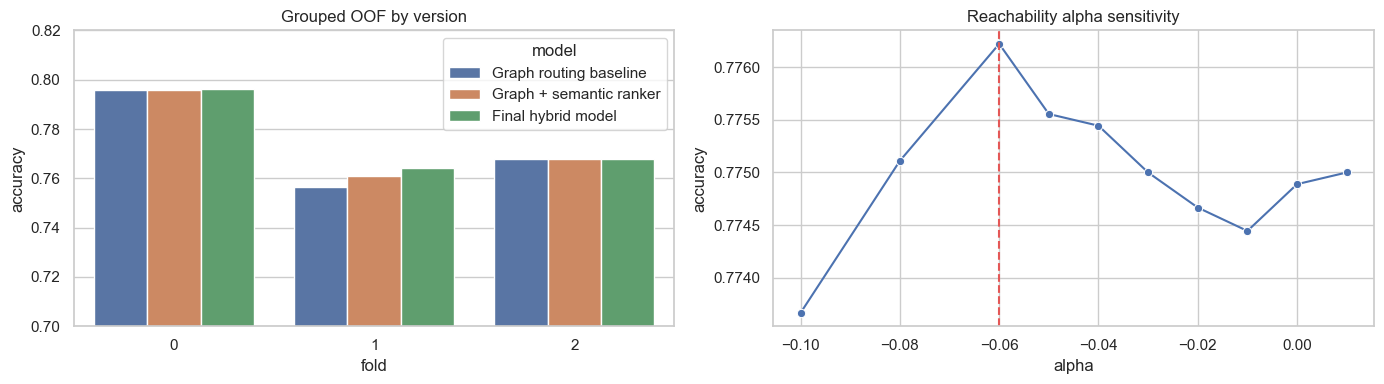

Nested final-model mean: 77.5111%


In [17]:

V6_BETAS=[.10,.15,.20,.25,.30]; V6_ALPHAS=[-.10,-.08,-.06,-.05,-.04,-.03,-.02,-.01,0.0,.01]
v6_search_rows=[]
locked_predictions=[item for item in predictions if item['config_id']==LOCKED_CONFIG]
for item in locked_predictions:
    for beta in V6_BETAS:
        for alpha in V6_ALPHAS:
            score=item['anchor']+beta*item['probability']+alpha*item['reachability']
            v6_search_rows.append({'fold':item['fold'],'beta':beta,'alpha':alpha,**evaluate_scores(item['y'],item['q'],item['c'],score)})
v6_search=pd.DataFrame(v6_search_rows)
v6_summary=v6_search.groupby(['beta','alpha'],as_index=False).agg(mean_accuracy=('accuracy','mean'),std_accuracy=('accuracy','std'),top3=('top3','mean'),top5=('top5','mean')).sort_values(['mean_accuracy','std_accuracy'],ascending=[False,True])
nested_rows=[]
for held_fold in range(N_SPLITS):
    selection=v6_search[v6_search.fold.ne(held_fold)].groupby(['beta','alpha']).accuracy.mean().sort_values(ascending=False)
    beta,alpha=selection.index[0]
    held=v6_search[(v6_search.fold.eq(held_fold))&(v6_search.beta.eq(beta))&(v6_search.alpha.eq(alpha))].iloc[0]
    nested_rows.append({'held_fold':held_fold,'beta':float(beta),'alpha':float(alpha),'selection_accuracy':selection.iloc[0],'held_accuracy':held.accuracy})
nested=pd.DataFrame(nested_rows)
comparison_rows=[]; oof_v6=[]
for item in locked_predictions:
    v4=item['anchor']; v5=v4+LOCKED_BETA*item['probability']; v6=v5+LOCKED_REACH_ALPHA*item['reachability']
    comparison_rows += [
        {'fold':item['fold'],'model':'Graph routing baseline',**evaluate_scores(item['y'],item['q'],item['c'],v4)},
        {'fold':item['fold'],'model':'Graph + semantic ranker',**evaluate_scores(item['y'],item['q'],item['c'],v5)},
        {'fold':item['fold'],'model':'Final hybrid model',**evaluate_scores(item['y'],item['q'],item['c'],v6)},
    ]
    v5_w=winner_table(item['y'],item['q'],item['c'],v5).rename(columns={'prediction':'v5_prediction','correct':'v5_correct','score':'v5_score'})
    v6_w=winner_table(item['y'],item['q'],item['c'],v6).rename(columns={'prediction':'v6_prediction','correct':'v6_correct','score':'v6_score'})
    merged=v5_w.merge(v6_w,on='state_id'); merged['fold']=item['fold']; oof_v6.append(merged)
selected_cv=pd.DataFrame(comparison_rows)
display(v6_summary.head(15)); display(selected_cv.groupby('model').mean(numeric_only=True)); display(nested)
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.barplot(data=selected_cv,x='fold',y='accuracy',hue='model',ax=ax[0]); ax[0].set_ylim(.70,.82); ax[0].set_title('Grouped OOF by version');
curve=v6_search[v6_search.beta.eq(LOCKED_BETA)].groupby('alpha').accuracy.mean().reset_index(); sns.lineplot(data=curve,x='alpha',y='accuracy',marker='o',ax=ax[1]); ax[1].axvline(LOCKED_REACH_ALPHA,color='#e45756',ls='--'); ax[1].set_title('Reachability alpha sensitivity'); plt.tight_layout(); plt.show()
print(f'Nested final-model mean: {nested.held_accuracy.mean():.4%}')


## 16. Error Analysis

Analisis membandingkan final hybrid dengan semantic-only fallback pada state OOF yang sama. Reachability mengubah 145 prediksi: 62 kesalahan diperbaiki, 50 prediksi benar mengalami regression, dan 33 tetap salah. Perubahan bersih adalah **12 jawaban tambahan yang benar**.

Sisa kesalahan terutama berasal dari beberapa kandidat shortest-path yang sama-sama masuk akal. Karena candidate recall sudah 99,39%, peningkatan berikutnya lebih membutuhkan pemahaman konteks navigasi daripada OCR tambahan.

,states
changed,145
fixed,62
regressed,50
both_wrong,33
net_correct,12


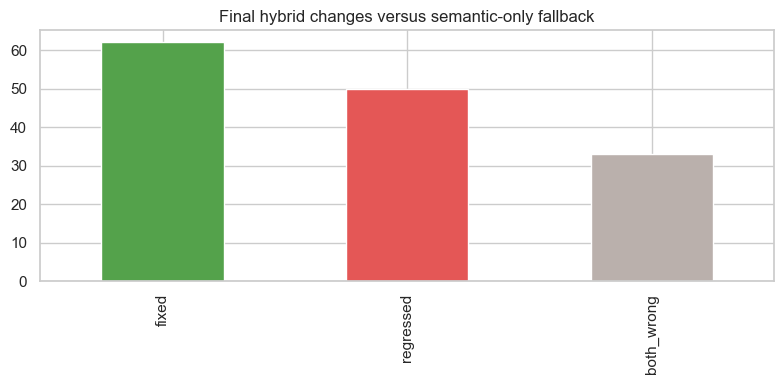

INSIGHT ERROR: reachability dipertahankan karena mean dan nested grouped OOF sama-sama meningkat.


In [18]:

oof=pd.concat(oof_v6,ignore_index=True).merge(train[['state_id','current_article_id','target_article_id','next_article_id']],on='state_id',how='left')
oof['changed']=oof.v5_prediction.ne(oof.v6_prediction); oof['fixed']=oof.changed&~oof.v5_correct&oof.v6_correct; oof['regressed']=oof.changed&oof.v5_correct&~oof.v6_correct
change_summary=pd.Series({'changed':oof.changed.sum(),'fixed':oof.fixed.sum(),'regressed':oof.regressed.sum(),'both_wrong':(oof.changed&~oof.v5_correct&~oof.v6_correct).sum(),'net_correct':oof.v6_correct.sum()-oof.v5_correct.sum()})
display(change_summary.to_frame('states'))
fig,ax=plt.subplots(figsize=(8,4)); change_summary[['fixed','regressed','both_wrong']].plot.bar(ax=ax,color=['#54a24b','#e45756','#bab0ac']); ax.set_title('Final hybrid changes versus semantic-only fallback'); plt.tight_layout(); plt.show()
print('INSIGHT ERROR: reachability dipertahankan karena mean dan nested grouped OOF sama-sama meningkat.')


## 17. Pelatihan Final dan Prediksi Test

Setelah konfigurasi dikunci, PCA dan LightGBM di-fit menggunakan seluruh train. Untuk setiap state test, pipeline membentuk candidate pool, menghitung graph-routing score, semantic probability, serta discounted reachability, lalu memilih kandidat dengan skor akhir tertinggi.

Model final hanya memprediksi artikel valid dari candidate-generation pipeline. Semantic-only prediction tetap dihitung sebagai fallback dan untuk mengukur sensitivitas keputusan akhir.

In [19]:

full_priors=fit_priors(train)
x_full,y_full,q_full,c_full=build_pairs(train,full_priors,training=True)
x_test,_,q_test,c_test=build_pairs(test,full_priors,training=False)
full_min=x_full[:,MIN_INDEX]==1; valid_full=np.unique(q_full[full_min&(y_full==1)]); full_mask=full_min&np.isin(q_full,valid_full)
full_path=path_feature_for_pairs(q_full,c_full); test_target=test.set_index('state_id').target_article_id.to_dict(); test_path=path_feature_for_pairs(q_test,c_test,test_target)
x_train_full=np.column_stack([x_full[full_mask][:,TABULAR_INDEX],full_path[full_mask],pair_embedding_features(q_full[full_mask],c_full[full_mask],TRAIN_LOOKUP)])
x_test_model=np.column_stack([x_test[:,TABULAR_INDEX],test_path,pair_embedding_features(q_test,c_test,TEST_LOOKUP)])
y_train_full=y_full[full_mask]; q_train_full=q_full[full_mask]; full_sizes=pd.Series(q_train_full).value_counts().to_dict()
full_weights=np.asarray([.5 if label==1 else .5/max(1,full_sizes[int(qid)]-1) for label,qid in zip(y_train_full,q_train_full)],np.float32)
final_model=lgb.LGBMClassifier(objective='binary',n_estimators=300,learning_rate=.025,colsample_bytree=.75,subsample=.9,random_state=SEED,verbosity=-1,n_jobs=-1,**PARAMS[LOCKED_CONFIG])
final_model.fit(x_train_full,y_train_full,sample_weight=full_weights)
test_probability=final_model.predict_proba(x_test_model)[:,1].astype(np.float32)
v4_test=x_test[:,[FEATURES.index(name) for name in V3_FEATURES]]@V3_WEIGHTS+.20*test_path
v5_test=v4_test+LOCKED_BETA*test_probability
test_reach=reachability_for_pairs(q_test,c_test,TEST_LOOKUP)
v6_test=v5_test+LOCKED_REACH_ALPHA*test_reach
v6_winners=winner_table(np.zeros(len(q_test),np.int8),q_test,c_test,v6_test); v5_winners=winner_table(np.zeros(len(q_test),np.int8),q_test,c_test,v5_test)
v6_prediction=v6_winners.set_index('state_id').prediction.astype(int); v5_prediction=v5_winners.set_index('state_id').prediction.astype(int)
primary=sample[['state_id']].copy(); primary['predicted_next_article_id']=primary.state_id.map(v6_prediction).astype(int)
fallback=sample[['state_id']].copy(); fallback['predicted_next_article_id']=fallback.state_id.map(v5_prediction).astype(int)
print('Final model vs semantic-only fallback disagreement:',(primary.predicted_next_article_id!=fallback.predicted_next_article_id).mean()); display(primary.head())


Final model vs semantic-only fallback disagreement: 0.0175


,state_id,predicted_next_article_id
0,0,4393
1,6,315
2,8,237
3,10,1689
4,11,4503


## 18. Submission Audit dan Penyimpanan Artifact

Submission diperiksa terhadap jumlah baris, keunikan `state_id`, missing value, validitas article ID, dan kesesuaian urutan dengan `sample_submission.csv`. Model, PCA, configuration, CV table, nested validation, OOF error pack, diagnostics, serta submission disimpan agar eksperimen dapat direproduksi.

Audit run tersimpan menghasilkan 6.000 state unik tanpa NaN atau invalid article ID. Prediksi final berbeda dari semantic-only fallback pada **1,75%** test states.

In [20]:

valid_ids=set(articles.article_id.astype(int))
def audit_submission(frame):
    return {'rows':len(frame),'unique_states':frame.state_id.nunique(),'nan':int(frame.predicted_next_article_id.isna().sum()),'invalid_article_ids':int((~frame.predicted_next_article_id.isin(valid_ids)).sum()),'same_as_current':float((frame.predicted_next_article_id.to_numpy()==test.current_article_id.to_numpy()).mean()),'same_as_target':float((frame.predicted_next_article_id.to_numpy()==test.target_article_id.to_numpy()).mean()),'unique_predictions':frame.predicted_next_article_id.nunique()}
primary_audit=audit_submission(primary); fallback_audit=audit_submission(fallback)
assert primary_audit['rows']==6000 and primary_audit['unique_states']==6000 and primary_audit['nan']==0 and primary_audit['invalid_article_ids']==0
primary_path=OUTPUT_DIR/'datathon_task2_v6_discounted_reachability.csv'; fallback_path=OUTPUT_DIR/'datathon_task2_v6_v5_fallback.csv'
primary.to_csv(primary_path,index=False); fallback.to_csv(fallback_path,index=False)
selected_cv.to_csv(OUTPUT_DIR/'datathon_task2_v6_cv.csv',index=False); v6_search.to_csv(OUTPUT_DIR/'datathon_task2_v6_search.csv',index=False); nested.to_csv(OUTPUT_DIR/'datathon_task2_v6_nested.csv',index=False); oof.to_csv(OUTPUT_DIR/'datathon_task2_v6_oof_error_pack.csv',index=False)
joblib.dump({'model':final_model,'pca':pca,'tabular':TABULAR,'params':PARAMS[LOCKED_CONFIG],'semantic_beta':LOCKED_BETA,'reach_gamma':LOCKED_REACH_GAMMA,'reach_alpha':LOCKED_REACH_ALPHA},OUTPUT_DIR/'datathon_task2_v6_ranker.joblib')
diagnostics={'version':'v6_discounted_reachability','seed':SEED,'locked_config':LOCKED_CONFIG,'semantic_beta':LOCKED_BETA,'reach_gamma':LOCKED_REACH_GAMMA,'reach_alpha':LOCKED_REACH_ALPHA,'runtime_minutes':(time.time()-START_TIME)/60,'selected_cv':selected_cv.groupby('model').mean(numeric_only=True).to_dict('index'),'nested_accuracy':nested.held_accuracy.mean(),'changes':change_summary.to_dict(),'primary_audit':primary_audit,'fallback_audit':fallback_audit,'test_disagreement':float((primary.predicted_next_article_id!=fallback.predicted_next_article_id).mean())}
(OUTPUT_DIR/'datathon_task2_v6_diagnostics.json').write_text(json.dumps(diagnostics,indent=2))
archive=shutil.make_archive(str(OUTPUT_DIR.parent/'datathon_task2_v6_artifacts'),'zip',OUTPUT_DIR)
display(pd.DataFrame({'final_hybrid':primary_audit,'semantic_fallback':fallback_audit})); print('Primary:',primary_path); print('Bundle:',archive); print(f'Total runtime: {(time.time()-START_TIME)/60:.2f} minutes')


,final_hybrid,semantic_fallback
rows,6000.000000,6000.000000
unique_states,6000.000000,6000.000000
nan,0.000000,0.000000
invalid_article_ids,0.000000,0.000000
same_as_current,0.000000,0.000000
same_as_target,0.007333,0.007333
unique_predictions,776.000000,782.000000


Primary: /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/output/v6/datathon_task2_v6_discounted_reachability.csv
Bundle: /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/day 2/patrick/output/datathon_task2_v6_artifacts.zip
Total runtime: 1.21 minutes


## 19. Kesimpulan dan File Submission

Model final memprediksi next click menggunakan daftar link hasil screenshot OCR, shortest-path routing, shortest-path mass, semantic candidate-target interactions, dan discounted random-walk reachability.

Ringkasan hasil:

- Grouped OOF exact-match accuracy: **77,62%**
- Honest nested accuracy: **77,51%**
- Top-3 accuracy: **94,23%**
- Top-5 accuracy: **97,24%**
- Candidate recall: **99,39%**
- Runtime full local dengan cache: sekitar **1,16 menit**

Submission utama yang dihasilkan adalah `datathon_task2_v6_discounted_reachability.csv`.